# Diseño y Preparación de Datos NoSQL del CNIT 2025 
## Caso de estudio: Vías de Comunicación (camino_l)

## 1. Introducción y Fuente de Datos
La presente práctica tiene como propósito desarrollar el diseño y preparación de una base de datos NoSQL a partir de información geoespacial contenida en el Conjunto Nacional de Información Topográfica (CNIT) escala 1:50 000, 2025. 

El trabajo se enfoca en la temática de Vías de Comunicación, utilizando como caso piloto la capa `camino_l`, con el fin de implementar un flujo completo de exploración, limpieza, transformación y carga de datos geoespaciales en una base de datos orientada a documentos. 

La estructura propuesta busca ser escalable para incorporar posteriormente el resto de las clases temáticas del CNIT 2025.
### 1.1 Objetivo de la práctica 
Diseñar y preparar una base de datos NoSQL utilizando información geoespacial del CNIT 2025, aplicando procesos de exploración, limpieza, transformación y carga de datos que permitan almacenar y consultar objetos geográficos de manera eficiente.
### 1.2 Descripción del Conjunto Nacional de Información Topográfica (CNIT 2025)
El Conjunto Nacional de Información Topográfica (CNIT) escala 1:50 000, 2025, es un conjunto de datos geoespaciales elaborado por el Instituto Nacional de Estadística y Geografía (INEGI), cuyo objetivo es representar de manera estructurada los elementos físicos y culturales presentes en el territorio nacional. 

La información se encuentra organizada mediante objetos geográficos clasificados por temas y subtemas, incorporando geometrías de tipo punto, línea y área, además de sus respectivos atributos descriptivos. 

Para este proyecto, los datos se encuentran almacenados en formato GeoPackage (GPKG), lo que facilita su consulta y procesamiento mediante herramientas de análisis geoespacial.
### 1.3 Justificación de la selección de Vías de Comunicación 
La temática de Vías de Comunicación fue seleccionada como caso de estudio debido a la relevancia que tienen estos elementos para la representación cartográfica y el análisis territorial. 

Asimismo, esta temática incluye distintos tipos de objetos lineales, permitiendo evaluar la capacidad de un modelo NoSQL para almacenar y gestionar información geoespacial de manera flexible. 

Entre los objetos considerados dentro de esta temática se encuentran caminos, carreteras, vialidades, vías férreas, puentes y túneles.
### 1.4 Alcance del caso de estudio
Debido al volumen de información contenido en el CNIT 2025, se trabajará inicialmente con la capa `camino_l` como caso piloto. 

La estructura diseñada permitirá incorporar posteriormente otras capas pertenecientes a la temática de Vías de Comunicación sin necesidad de modificar el modelo de datos propuesto. 

El alcance de esta práctica comprende: 
- Exploración de los datos geoespaciales. 
- Construcción del diccionario de datos. 
- Diseño de un modelo NoSQL orientado a documentos. 
- Limpieza y validación de información. 
- Transformación de geometrías a formato GeoJSON. 
- Carga inicial en MongoDB. 
- Consultas básicas de validación. 
### 1.5 Descripción de la capa piloto: camino_l
La capa `camino_l` representa elementos lineales correspondientes a caminos identificados dentro del territorio nacional. 

De acuerdo con el Diccionario de Datos Topográficos (DDT), esta clase incluye distintas categorías funcionales, entre las que se encuentran: 
- Brecha 
- Terracería 
- Vereda 

Estas categorías permiten evaluar distintos escenarios de clasificación y almacenamiento dentro de una base de datos NoSQL, manteniendo una estructura homogénea para la representación de objetos geográficos lineales.

## 2. Exploración del GeoPackage
El primer paso consiste en realizar una exploración inicial del archivo GeoPackage correspondiente al CNIT 2025. Esta etapa permite identificar las capas disponibles, conocer su tipo de geometría y cuantificar el número de registros almacenados en cada una. 
### 2.1 Carga de librerías


In [84]:
# Manejo de datos espaciales
import geopandas as gpd
import pandas as pd
import pyogrio
from pathlib import Path

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


### 2.2 Conexión al GeoPackage
Se define la ruta del archivo GeoPackage que contiene el Conjunto Nacional de Información Topográfica (CNIT 2025). > Sustituir la ruta por la ubicación real del archivo en el equipo.

In [85]:
ruta_gpkg = r"D:\EXTRACCION TOPOGRAFICA\2025\CNIT2025\PUBLICACION\794551163047_gpk\conjunto_de_datos\continuo2025.gpkg" 
Path(ruta_gpkg).exists()

True

### 2.3 Inventario de capas disponibles
Se obtiene el listado completo de capas contenidas en el GeoPackage.

In [86]:
import pyogrio

capas = pyogrio.list_layers(ruta_gpkg)

df_capas = pd.DataFrame(
    capas,
    columns=["Capa", "Geometría"]
)

print(f"Total de capas encontradas: {len(df_capas)}")

df_capas

Total de capas encontradas: 95


,Capa,Geometría
0,acueducto_l,LineString
1,aerodromo_a,Polygon
2,area_publica_a,Polygon
3,banco_mater_p,Point
4,banco_nivel_p,Point
...,...,...
90,zona_a,MultiPolygon
91,manzana_a,Polygon
92,cuerpo_agua_a,MultiPolygon
93,localidad_p,Point


### 2.4 Identificación del tipo de geometría por capa
La exploración inicial del GeoPackage permitió identificar que el CNIT 2025 contiene 95 capas geográficas distribuidas entre geometrías de tipo punto, línea y área. 

La información obtenida evidencia la naturaleza heterogénea del conjunto de datos y confirma la presencia de objetos geográficos representados mediante geometrías simples y multiparte. 

La tabla generada en el apartado anterior muestra para cada capa su respectivo tipo de geometría.

### 2.5 Conteo de registros por capa
Con el propósito de dimensionar el volumen de información contenido en cada capa, se contabiliza el número de registros geográficos almacenados dentro del GeoPackage. 

Esta información permitirá identificar las capas con mayor cantidad de entidades y seleccionar aquellas que serán consideradas para el desarrollo del modelo NoSQL.

In [87]:
resumen_capas = []

for capa in df_capas["Capa"]:

    gdf = gpd.read_file(
        ruta_gpkg,
        layer=capa
    )

    resumen_capas.append({
        "Capa": capa,
        "Geometría": gdf.geom_type.iloc[0] if len(gdf) > 0 else None,
        "Registros": len(gdf)
    })

inventario = pd.DataFrame(resumen_capas)

inventario

,Capa,Geometría,Registros
0,acueducto_l,LineString,22220
1,aerodromo_a,Polygon,89
2,area_publica_a,Polygon,18069
3,banco_mater_p,Point,5047
4,banco_nivel_p,Point,70781
...,...,...,...
90,zona_a,MultiPolygon,2146
91,manzana_a,Polygon,2276412
92,cuerpo_agua_a,MultiPolygon,455913
93,localidad_p,Point,241592


In [88]:
#Guardar resultados del inventario
inventario.to_csv(
    "inventario_capas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Inventario exportado")


Inventario exportado


Se ordenan las capas de acuerdo con el número de registros para identificar aquellas con mayor volumen de información.

In [89]:
inventario.sort_values(
    by="Registros",
    ascending=False
).head(20)

,Capa,Geometría,Registros
20,edificacion_p,Point,4132640
16,curva_nivel_l,LineString,3033618
14,corriente_ag_l,LineString,2427848
91,manzana_a,Polygon,2276412
86,vialidad_l,LineString,2261035
6,camino_l,LineString,638594
92,cuerpo_agua_a,MultiPolygon,455913
5,bordo_l,LineString,360000
93,localidad_p,Point,241592
73,referencia_g_p,Point,132006


La distribución de registros por capa muestra una alta variabilidad en el volumen de información almacenada dentro del CNIT 2025.

Entre las capas con mayor cantidad de entidades destacan aquellas asociadas a la representación detallada del territorio y de los asentamientos humanos, lo que evidencia la complejidad y riqueza temática del conjunto de datos.

Este análisis permitió identificar el tamaño relativo de cada capa y orientar la selección de una temática piloto para el diseño inicial de la base de datos NoSQL.

### 2.6 Resumen de las capas de Vías de Comunicación
A partir del inventario general del GeoPackage se identifican las capas correspondientes a la temática de Vías de Comunicación. 

Estas capas constituyen el universo de información que podrá incorporarse progresivamente al modelo NoSQL diseñado para este proyecto. 

El presente trabajo se enfoca inicialmente en la capa `camino_l`, sin embargo, la estructura propuesta permitirá integrar posteriormente el resto de los objetos relacionados con la movilidad y conectividad territorial..

In [90]:
capas_vias = inventario[
    inventario["Capa"].str.contains(
        "camino|carretera|vialidad|via_ferrea|puente|tunel",
        case=False,
        regex=True
    )
]

capas_vias.sort_values(
    by="Registros",
    ascending=False
)

,Capa,Geometría,Registros
86,vialidad_l,LineString,2261035
6,camino_l,LineString,638594
9,carretera_l,LineString,39321
69,puente_l,LineString,29484
85,via_ferrea_l,LineString,603
83,tunel_l,LineString,515


## 3. Análisis y Diccionario de Datos de camino_l
### 3.1 Carga de la capa camino_l
Con el propósito de conocer la estructura detallada de la información, se carga la capa `camino_l`, correspondiente a los caminos representados dentro del Conjunto Nacional de Información Topográfica 2025. 

Esta capa constituye el caso de estudio seleccionado para el diseño del modelo NoSQL debido a la diversidad de categorías que representa y a su relevancia dentro de la temática de Vías de Comunicación.

In [91]:
gdf_camino = gpd.read_file(
    ruta_gpkg,
    layer="camino_l"
)

gdf_camino.head()

,id,nom_obj,codigo,calif_pos,tipo,clase_geo,geometry
0,326190921,Camino,3171.0,Definida,Brecha,Servicios e instalaciones,"LINESTRING (-100.56124 20.16551, -100.56095 20..."
1,327792345,Camino,3173.0,Definida,Terracería,Servicios e instalaciones,"LINESTRING (-96.64207 19.3143, -96.64254 19.31..."
2,34233237,Camino,3171.0,Definida,Brecha,Servicios e instalaciones,"LINESTRING (-92.82649 16.55708, -92.82617 16.5..."
3,328056650,Camino,3171.0,Definida,Brecha,Servicios e instalaciones,"LINESTRING (-100.1094 23.42868, -100.10951 23...."
4,328826646,Camino,3173.0,Definida,Terracería,Servicios e instalaciones,"LINESTRING (-97.00261 18.75018, -97.00257 18.7..."


### 3.2 Inspección de atributos 
Se identifican los atributos disponibles en la capa con el fin de conocer la información descriptiva asociada a cada entidad geográfica.

In [92]:
gdf_camino.columns.tolist()

['id', 'nom_obj', 'codigo', 'calif_pos', 'tipo', 'clase_geo', 'geometry']

### 3.3 Tipos de datos de los campos 


In [93]:
gdf_camino.dtypes

id              int32
nom_obj           str
codigo        float64
calif_pos         str
tipo              str
clase_geo         str
geometry     geometry
dtype: object

### 3.4 Estadísticas generales de la capa
Se obtiene un resumen general de la capa, incluyendo el número de registros, número de campos y tipo de geometría predominante.

In [94]:
print(f"Registros: {len(gdf_camino)}")
print(f"Campos: {len(gdf_camino.columns)}")

gdf_camino.geom_type.value_counts()

Registros: 638594
Campos: 7


LineString    638594
Name: count, dtype: int64

### 3.5 Identificación de dominios y categorías
Con el propósito de identificar los valores categóricos asociados a los caminos, se analizan los dominios contenidos en el atributo `tipo`. 

Este atributo permite distinguir las diferentes categorías de caminos representadas en el CNIT 2025 y constituye uno de los elementos principales para la organización y consulta de la información dentro del modelo NoSQL.

In [95]:
gdf_camino["tipo"].value_counts()

tipo
Brecha        392218
Vereda        159609
Terracería     86767
Name: count, dtype: int64

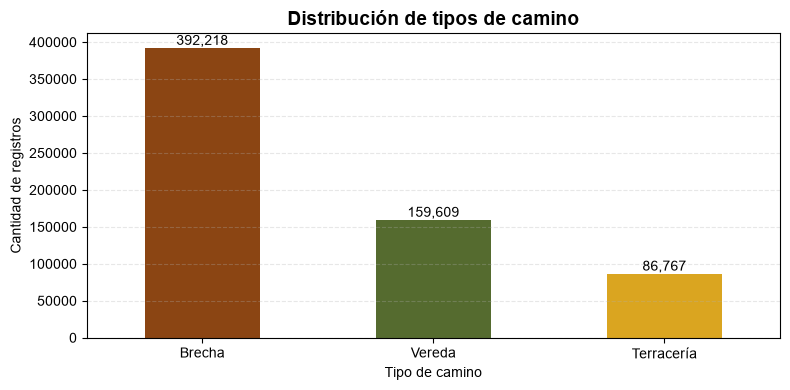

In [96]:
import matplotlib.pyplot as plt

ax = gdf_camino["tipo"].value_counts().plot(
    kind="bar",
    color=["saddlebrown", "darkolivegreen", "goldenrod"],
    figsize=(8, 4)
)

ax.set_title(
    "Distribución de tipos de camino",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Tipo de camino")
ax.set_ylabel("Cantidad de registros")

# Agregar etiquetas sobre cada barra
for barra in ax.patches:
    
    altura = barra.get_height()
    
    ax.annotate(
        f'{altura:,.0f}',
        (
            barra.get_x() + barra.get_width() / 2,
            altura
        ),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

El análisis del atributo `tipo` permitió identificar tres categorías principales dentro de la capa `camino_l`: Brecha, Vereda y Terracería.

La categoría con mayor representación es Brecha, con 392,218 registros, lo que representa aproximadamente el 61.4% del total de caminos registrados en la capa. Por su parte, Vereda concentra 159,609 registros (25.0%) y Terracería 86,767 registros (13.6%).

Esta distribución evidencia el predominio de caminos de tipo Brecha dentro del conjunto de datos analizado, lo cual resulta consistente con la cobertura nacional del CNIT 2025 y la representación de vías de comunicación de menor jerarquía presentes en amplias zonas rurales del territorio.

Las categorías identificadas serán utilizadas como criterio de clasificación dentro del modelo NoSQL propuesto, permitiendo realizar consultas, filtros y análisis específicos por tipo de camino.

### 3.6 Construcción del diccionario de datos
A partir de la estructura física identificada en el GeoPackage y de las definiciones contenidas en el Diccionario de Datos Topográficos (DDT), se construyó el diccionario de datos de la capa `camino_l`. 

La siguiente tabla resume los atributos que conforman la capa y su función dentro del modelo propuesto.

In [97]:
diccionario = pd.DataFrame({
    "Campo": gdf_camino.columns,
    "Tipo de dato": [str(x) for x in gdf_camino.dtypes]
})

diccionario

,Campo,Tipo de dato
0,id,int32
1,nom_obj,str
2,codigo,float64
3,calif_pos,str
4,tipo,str
5,clase_geo,str
6,geometry,geometry


| Campo | Descripción |
|---------|---------|
| id | Identificador único del objeto geográfico |
| nom_obj | Nombre oficial del objeto geográfico |
| codigo | Código de clasificación del objeto |
| calif_pos | Calificación posicional del objeto |
| tipo | Categoría del camino (Brecha, Terracería, Vereda, entre otros) |
| clase_geo | Clase geográfica a la que pertenece el objeto |
| geometry | Geometría espacial almacenada en formato vectorial |

## 4. Diseño del Modelo NoSQL
### 4.1 Selección del gestor NoSQL

Para el desarrollo de esta práctica se seleccionó MongoDB como sistema gestor de bases de datos NoSQL.

MongoDB utiliza un modelo orientado a documentos basado en estructuras JSON, lo que facilita el almacenamiento de información geográfica con atributos heterogéneos y geometrías representadas en formato GeoJSON.

La flexibilidad de este enfoque resulta adecuada para el manejo de objetos geográficos del CNIT 2025, ya que permite incorporar nuevos atributos y clases temáticas sin requerir modificaciones estructurales complejas.

### 4.2 Diseño de la base de datos `cnit2025`
Se propone la creación de una base de datos denominada `cnit2025`, destinada a almacenar información geoespacial proveniente del Conjunto Nacional de Información Topográfica. 

La estructura está diseñada para permitir la incorporación progresiva de otras capas temáticas, manteniendo un esquema flexible que facilite futuras extensiones relacionadas con el análisis y priorización de objetos geográficos.

### 4.3 Diseño de la colección `vias_comunicacion` 
Se propone una colección denominada `vias_comunicacion`, destinada al almacenamiento de los objetos geográficos relacionados con la movilidad y conectividad territorial. 

Inicialmente se incorporarán los registros provenientes de la capa `camino_l`; sin embargo, la colección está diseñada para integrar posteriormente otras capas como carreteras, vialidades, puentes, túneles y vías férreas. 

La utilización de una colección única permite centralizar la información temática y simplificar las consultas posteriores.

### 4.4 Definición de atributos del documento 
La estructura documental propuesta conserva los atributos identificados en la capa `camino_l`, incorporando además la geometría en formato GeoJSON para facilitar su almacenamiento dentro de MongoDB. 

La definición detallada de los campos y sus tipos de dato fue presentada previamente en el diccionario de datos, por lo que en esta sección se enfatiza únicamente su incorporación al modelo documental.

### 4.5 Representación de geometrías en formato GeoJSON
Las geometrías almacenadas en el GeoPackage serán transformadas al estándar GeoJSON para facilitar su almacenamiento y consulta dentro de MongoDB. 

La utilización de GeoJSON permite conservar la estructura espacial original de los objetos geográficos y habilita futuras operaciones de consulta geoespacial.


In [98]:
gdf_camino.iloc[0].geometry.__geo_interface__

{'type': 'LineString',
 'coordinates': ((-100.5612421, 20.1655121),
  (-100.56094775, 20.16554285),
  (-100.5604702, 20.165589349999998),
  (-100.5601441, 20.1656862),
  (-100.55980485, 20.16566605),
  (-100.5596291, 20.16563895),
  (-100.55937435, 20.1655776),
  (-100.5590849, 20.16550595),
  (-100.55888935, 20.1655005))}

### 4.6 Documento JSON de ejemplo

La siguiente estructura muestra un ejemplo simplificado de cómo será almacenado un objeto geográfico de la capa `camino_l` dentro de la colección `vias_comunicacion`.

```json
{
  "id": 1,
  "nom_obj": "CAMINO",
  "codigo": "...",
  "calif_pos": "...",
  "tipo": "Brecha",
  "clase_geo": "Camino",
  "geometry": {
    "type": "LineString",
    "coordinates": [...]
  }
}
```

La estructura documental propuesta permite almacenar tanto los atributos descriptivos como la componente espacial de cada objeto geográfico dentro de una misma entidad documental.

Este diseño facilita la incorporación de nuevas capas pertenecientes a la temática de Vías de Comunicación y constituye la base para la carga inicial de información en MongoDB.

## 5. Limpieza de Datos 
### 5.1 Identificación de valores nulos 
La identificación de valores nulos constituye una etapa fundamental dentro del proceso de limpieza de datos, ya que permite detectar información faltante que pueda afectar el análisis posterior o la carga de información en la base de datos NoSQL. 

Para la capa `camino_l` se realiza una revisión de los atributos con el fin de identificar campos que presenten valores vacíos o ausentes.

In [99]:
nulos = (
    gdf_camino.isnull()
    .sum()
    .reset_index()
)

nulos.columns = [
    "Campo",
    "Valores nulos"
]

nulos

,Campo,Valores nulos
0,id,0
1,nom_obj,0
2,codigo,0
3,calif_pos,0
4,tipo,0
5,clase_geo,0
6,geometry,0


El análisis de valores nulos indica que todos los atributos de la capa `camino_l` presentan información completa, sin registros con datos faltantes.

Este resultado evidencia la consistencia y calidad de la información contenida en el CNIT 2025 para la capa analizada, por lo que no fue necesario aplicar procedimientos de imputación o eliminación de registros asociados a valores nulos.

### 5.2 Identificación de registros duplicados
Se realiza la búsqueda de registros duplicados con el objetivo de identificar posibles redundancias dentro del conjunto de datos. 

La presencia de registros duplicados podría generar inconsistencias en el almacenamiento y análisis posterior de la información. 

In [100]:
duplicados = gdf_camino.duplicated().sum()

print(f"Registros duplicados encontrados: {duplicados}")

Registros duplicados encontrados: 0


### 5.3 Validación de geometrías
Las geometrías se validan para verificar que su estructura espacial sea correcta y compatible con los procesos de transformación y almacenamiento en formato GeoJSON.

Esta validación resulta especialmente importante para garantizar la integridad de la información geográfica durante la carga en MongoDB.

In [101]:
geometrias_validas = gdf_camino.geometry.is_valid.sum()

geometrias_invalidas = (
    len(gdf_camino) - geometrias_validas
)

print(f"Geometrías válidas: {geometrias_validas:,}")
print(f"Geometrías inválidas: {geometrias_invalidas:,}")

Geometrías válidas: 638,594
Geometrías inválidas: 0


### 5.4 Homologación de valores categóricos
Se revisa el atributo `tipo` para verificar la consistencia en la escritura de las categorías existentes.

La homologación de valores categóricos permite evitar inconsistencias derivadas de diferencias en mayúsculas, minúsculas o variantes ortográficas.


In [102]:
gdf_camino["tipo"].unique()

<StringArray>
['Brecha', 'Terracería', 'Vereda']
Length: 3, dtype: str

### 5.5 Resultados de la limpieza
Los procedimientos de limpieza aplicados a la capa `camino_l` permitieron verificar la calidad y consistencia de la información antes de iniciar el proceso de transformación y preparación de datos.

Las principales observaciones obtenidas fueron:

- No se identificaron valores nulos en los atributos analizados.
- No se identificaron registros duplicados.
- Las geometrías fueron evaluadas para verificar su validez espacial.
- Las categorías del atributo `tipo` presentan una estructura homogénea y consistente.

En consecuencia, la capa `camino_l` se encuentra en condiciones adecuadas para continuar con las etapas de transformación y carga al modelo NoSQL propuesto.


## 6. Transformación y Preparación de Datos 
### 6.1 Selección de atributos para MongoDB
A partir del análisis realizado sobre la capa `camino_l`, se seleccionaron los atributos necesarios para conservar la información descriptiva y espacial requerida por el modelo documental propuesto.

Los campos seleccionados permiten mantener la trazabilidad con respecto a la fuente original, al mismo tiempo que facilitan su almacenamiento y consulta dentro de MongoDB.



In [103]:
atributos_mongo = [
    "id",
    "nom_obj",
    "codigo",
    "calif_pos",
    "tipo",
    "clase_geo",
    "geometry"
]

atributos_mongo

['id', 'nom_obj', 'codigo', 'calif_pos', 'tipo', 'clase_geo', 'geometry']

### 6.2 Conversión de geometrías a GeoJSON
Las geometrías contenidas en la capa `camino_l` se transforman al formato GeoJSON, estándar ampliamente utilizado para el intercambio y almacenamiento de información geoespacial en sistemas orientados a documentos.

In [104]:
gdf_camino["geometry"].iloc[0].__geo_interface__

{'type': 'LineString',
 'coordinates': ((-100.5612421, 20.1655121),
  (-100.56094775, 20.16554285),
  (-100.5604702, 20.165589349999998),
  (-100.5601441, 20.1656862),
  (-100.55980485, 20.16566605),
  (-100.5596291, 20.16563895),
  (-100.55937435, 20.1655776),
  (-100.5590849, 20.16550595),
  (-100.55888935, 20.1655005))}

### 6.3 Creación de la estructura documental
Se construye una estructura documental que integra tanto los atributos descriptivos como la geometría de cada objeto geográfico.

Esta estructura servirá como base para la generación de documentos compatibles con MongoDB.

In [105]:
registro_ejemplo = gdf_camino.iloc[0]

documento = {
    "id": registro_ejemplo["id"],
    "nom_obj": registro_ejemplo["nom_obj"],
    "codigo": registro_ejemplo["codigo"],
    "calif_pos": registro_ejemplo["calif_pos"],
    "tipo": registro_ejemplo["tipo"],
    "clase_geo": registro_ejemplo["clase_geo"],
    "geometry": registro_ejemplo["geometry"].__geo_interface__
}

documento

{'id': np.int32(326190921),
 'nom_obj': 'Camino',
 'codigo': np.float64(3171.0),
 'calif_pos': 'Definida',
 'tipo': 'Brecha',
 'clase_geo': 'Servicios e instalaciones',
 'geometry': {'type': 'LineString',
  'coordinates': ((-100.5612421, 20.1655121),
   (-100.56094775, 20.16554285),
   (-100.5604702, 20.165589349999998),
   (-100.5601441, 20.1656862),
   (-100.55980485, 20.16566605),
   (-100.5596291, 20.16563895),
   (-100.55937435, 20.1655776),
   (-100.5590849, 20.16550595),
   (-100.55888935, 20.1655005))}}

### 6.4 Generación de documentos JSON
A partir de los registros contenidos en la capa `camino_l`, se generan documentos con estructura JSON listos para su incorporación a una colección de MongoDB.

In [106]:
documentos_json = []

for _, fila in gdf_camino.head(100).iterrows():

    documentos_json.append({
        "id": fila["id"],
        "nom_obj": fila["nom_obj"],
        "codigo": fila["codigo"],
        "calif_pos": fila["calif_pos"],
        "tipo": fila["tipo"],
        "clase_geo": fila["clase_geo"],
        "geometry": fila["geometry"].__geo_interface__
    })

len(documentos_json)

100

### 6.5 Validación de los documentos generados
Se verifica que los documentos generados contengan la estructura esperada y que incorporen correctamente tanto los atributos descriptivos como la componente espacial en formato GeoJSON.

In [107]:
documentos_json[0]

{'id': 326190921,
 'nom_obj': 'Camino',
 'codigo': 3171.0,
 'calif_pos': 'Definida',
 'tipo': 'Brecha',
 'clase_geo': 'Servicios e instalaciones',
 'geometry': {'type': 'LineString',
  'coordinates': ((-100.5612421, 20.1655121),
   (-100.56094775, 20.16554285),
   (-100.5604702, 20.165589349999998),
   (-100.5601441, 20.1656862),
   (-100.55980485, 20.16566605),
   (-100.5596291, 20.16563895),
   (-100.55937435, 20.1655776),
   (-100.5590849, 20.16550595),
   (-100.55888935, 20.1655005))}}

## 7. Carga Inicial y Administración de la Base de Datos 
### 7.1 Preparación para la carga en MongoDB

Una vez generados los documentos JSON a partir de la capa `camino_l`, se preparó la estructura necesaria para su inserción en una base de datos MongoDB.

La base de datos propuesta se denomina `cnit2025` y contará inicialmente con una colección denominada `vias_comunicacion`, destinada al almacenamiento de objetos geográficos relacionados con la conectividad terrestre.

La estructura documental generada cumple con los requisitos necesarios para ser insertada directamente en MongoDB mediante el uso de la biblioteca PyMongo.

### 7.2 Creación de la base de datos cnit2025
La base de datos propuesta para almacenar la información geoespacial del CNIT 2025 se denomina `cnit2025`.

Esta base de datos fue diseñada para alojar inicialmente la temática de Vías de Comunicación, permitiendo la incorporación progresiva de otras clases geográficas contenidas en el Conjunto Nacional de Información Topográfica.

In [108]:
from pymongo import MongoClient

cliente = MongoClient(
    "mongodb://localhost:27017/"
)

db = cliente["cnit2025"]

db

Database(MongoClient(host=['localhost:27017'], document_class=dict, tz_aware=False, connect=True), 'cnit2025')

### 7.3 Creación de la colección `vias_comunicacion`
Dentro de la base de datos `cnit2025` se propone una colección denominada `vias_comunicacion`.

Esta colección almacenará objetos geográficos correspondientes a caminos, carreteras, vialidades, túneles, puentes y vías férreas, manteniendo una estructura documental homogénea.

In [109]:
coleccion = db["vias_comunicacion"]

coleccion

Collection(Database(MongoClient(host=['localhost:27017'], document_class=dict, tz_aware=False, connect=True), 'cnit2025'), 'vias_comunicacion')

### 7.4 Inserción de documentos desde Python
Los documentos generados durante la etapa de preparación de datos pueden incorporarse a MongoDB mediante la operación `insert_many()`. Esta operación permite insertar múltiples documentos en una sola transacción.

In [110]:
# Inserción propuesta

# coleccion.insert_many(documentos_json)


Durante las pruebas se preparó el código de inserción utilizando la biblioteca PyMongo. La ejecución de la operación no se completó debido a que el servicio MongoDB no se encontraba instalado ni disponible en el entorno de trabajo.

No obstante, los documentos JSON fueron generados correctamente y se encuentran listos para su incorporación a la base de datos propuesta.

## 8. Consultas de Validación 
### 8.1 Conteo total de documentos generados
Como parte del proceso de validación, se verifica la cantidad de documentos JSON generados a partir de la capa `camino_l`.

Este procedimiento permite confirmar que la estructura documental fue creada correctamente antes de su incorporación a MongoDB.

In [111]:
print(
    f"Documentos generados: {len(documentos_json):,}"
)

Documentos generados: 100


### 8.2 Conteo de registros por tipo de camino
Se analiza la distribución de los documentos generados de acuerdo con la categoría almacenada en el atributo `tipo`.

In [112]:
gdf_camino["tipo"].value_counts()

tipo
Brecha        392218
Vereda        159609
Terracería     86767
Name: count, dtype: int64

### 8.3 Consulta de documentos de tipo Brecha
Se muestra un ejemplo de documento correspondiente a la categoría Brecha con el propósito de verificar la correcta incorporación de atributos y geometría.

In [113]:
siguiente = next(
    doc for doc in documentos_json
    if doc["tipo"] == "Brecha"
)

siguiente

{'id': 326190921,
 'nom_obj': 'Camino',
 'codigo': 3171.0,
 'calif_pos': 'Definida',
 'tipo': 'Brecha',
 'clase_geo': 'Servicios e instalaciones',
 'geometry': {'type': 'LineString',
  'coordinates': ((-100.5612421, 20.1655121),
   (-100.56094775, 20.16554285),
   (-100.5604702, 20.165589349999998),
   (-100.5601441, 20.1656862),
   (-100.55980485, 20.16566605),
   (-100.5596291, 20.16563895),
   (-100.55937435, 20.1655776),
   (-100.5590849, 20.16550595),
   (-100.55888935, 20.1655005))}}

### 8.4 Consulta de documentos de tipo Terracería

Se presenta un ejemplo de documento perteneciente a la categoría Terracería.

In [114]:
siguiente = next(
    doc for doc in documentos_json
    if doc["tipo"] == "Terracería"
)

siguiente

{'id': 327792345,
 'nom_obj': 'Camino',
 'codigo': 3173.0,
 'calif_pos': 'Definida',
 'tipo': 'Terracería',
 'clase_geo': 'Servicios e instalaciones',
 'geometry': {'type': 'LineString',
  'coordinates': ((-96.64206659999999, 19.3142956),
   (-96.6425365, 19.31437425),
   (-96.64284985, 19.31447495),
   (-96.64304455, 19.3144705),
   (-96.6433467, 19.314389900000002),
   (-96.6435862, 19.314327249999998),
   (-96.6439197, 19.31425785),
   (-96.64419945, 19.3142244),
   (-96.64431805, 19.3142117),
   (-96.6445574, 19.314186),
   (-96.64487535, 19.314105650000002),
   (-96.64500964999999, 19.3141012),
   (-96.6451887, 19.3141325),
   (-96.64543265, 19.31425785),
   (-96.64571245, 19.31443915),
   (-96.64591835, 19.314512999999998),
   (-96.64606605, 19.314580149999998),
   (-96.6462608, 19.3145533),
   (-96.64643535, 19.314512999999998),
   (-96.6465697, 19.31443995),
   (-96.64659295, 19.31440825),
   (-96.6466864, 19.314208700000002),
   (-96.6468251, 19.31401455),
   (-96.646941, 19.3

La salida mostrada fue truncada automáticamente por el entorno de ejecución debido al número de vértices contenidos en la geometría. No obstante, se verificó que la estructura espacial fue convertida correctamente a formato GeoJSON.

### 8.5 Consulta de documentos de tipo Vereda
Se presenta un ejemplo de documento perteneciente a la categoría Vereda.

In [115]:
siguiente = next(
    doc for doc in documentos_json
    if doc["tipo"] == "Vereda"
)

siguiente

{'id': 1061746,
 'nom_obj': 'Camino',
 'codigo': 3172.0,
 'calif_pos': 'Definida',
 'tipo': 'Vereda',
 'clase_geo': 'Servicios e instalaciones',
 'geometry': {'type': 'LineString',
  'coordinates': ((-102.73748735, 26.9025551),
   (-102.73756445000001, 26.90262405),
   (-102.73766485, 26.90268815),
   (-102.73780550000001, 26.902745099999997),
   (-102.7380186, 26.9028397),
   (-102.73815635, 26.9029253),
   (-102.73838595, 26.9032129),
   (-102.73856055, 26.903576299999997),
   (-102.7386631, 26.903783599999997),
   (-102.7387124, 26.9039907),
   (-102.73881465, 26.904342399999997),
   (-102.7389199, 26.90477545),
   (-102.7390017, 26.90498515),
   (-102.73911635, 26.9051808),
   (-102.73922295, 26.905430449999997),
   (-102.7393781, 26.9058101),
   (-102.73958845, 26.9062183),
   (-102.73989305, 26.9068249),
   (-102.7400859, 26.90706435),
   (-102.7402554, 26.9072752),
   (-102.74051315, 26.90753385),
   (-102.7405833, 26.907635550000002),
   (-102.74081625, 26.907884199999998),
   

### 8.6 Verificación de la estructura GeoJSON
Finalmente, se valida que los documentos incorporen correctamente la información espacial utilizando la estructura GeoJSON propuesta para MongoDB.

In [116]:
{
    "tipo_geometria": documentos_json[0]["geometry"]["type"],
    "numero_vertices": len(
        documentos_json[0]["geometry"]["coordinates"]
    )
}

{'tipo_geometria': 'LineString', 'numero_vertices': 9}

La validación realizada confirmó que las geometrías fueron convertidas correctamente a formato GeoJSON. Adicionalmente, se verificó el tipo de geometría y la cantidad de vértices asociados a los objetos geográficos, garantizando su compatibilidad con futuras operaciones de almacenamiento y consulta espacial en MongoDB.

### 8.7 Resultado de la validación

La validación realizada sobre los documentos generados confirmó que:

- Los registros fueron transformados correctamente a formato JSON.
- Los atributos descriptivos fueron conservados durante el proceso de preparación.
- Las categorías de caminos fueron preservadas adecuadamente.
- Las geometrías fueron representadas mediante estructuras compatibles con GeoJSON.
- Los documentos resultantes se encuentran listos para su incorporación a una colección MongoDB.

Los resultados obtenidos demuestran que el proceso de diseño, limpieza y preparación de datos fue exitoso y cumple con los requisitos establecidos para el modelo NoSQL propuesto.

## 9. Gestión y consulta de datos
### 9.1 Verificación del conjunto documental

In [117]:
print("Total de documentos:", len(documentos_json))

print("\nCampos disponibles:")
for campo in documentos_json[0].keys():
    print("-", campo)

print("\nPrimer documento:")
documentos_json[0]

Total de documentos: 100

Campos disponibles:
- id
- nom_obj
- codigo
- calif_pos
- tipo
- clase_geo
- geometry

Primer documento:


{'id': 326190921,
 'nom_obj': 'Camino',
 'codigo': 3171.0,
 'calif_pos': 'Definida',
 'tipo': 'Brecha',
 'clase_geo': 'Servicios e instalaciones',
 'geometry': {'type': 'LineString',
  'coordinates': ((-100.5612421, 20.1655121),
   (-100.56094775, 20.16554285),
   (-100.5604702, 20.165589349999998),
   (-100.5601441, 20.1656862),
   (-100.55980485, 20.16566605),
   (-100.5596291, 20.16563895),
   (-100.55937435, 20.1655776),
   (-100.5590849, 20.16550595),
   (-100.55888935, 20.1655005))}}

### 9.2 Consulta básica por atributo
Como primera consulta se realiza una búsqueda por igualdad sobre el atributo tipo, seleccionando los documentos correspondientes a caminos clasificados como Brecha.

En MongoDB, la consulta equivalente sobre la colección sería:

db.vias_comunicacion.find({"tipo": "Brecha"})

Debido a que el entorno de trabajo no dispone de una instalación local de MongoDB, la funcionalidad de la consulta se reproduce sobre los documentos JSON previamente generados mediante Python.


In [118]:
# Consulta equivalente a:
# db.vias_comunicacion.find({"tipo": "Brecha"})

consulta_brecha = [
    doc for doc in documentos_json
    if doc.get("tipo") == "Brecha"
]

print("Documentos encontrados:", len(consulta_brecha))
print("\nPrimeros 5 resultados:")

for doc in consulta_brecha[:5]:
    print({
        "id": doc["id"],
        "nom_obj": doc["nom_obj"],
        "tipo": doc["tipo"],
        "calif_pos": doc["calif_pos"]
    })


Documentos encontrados: 61

Primeros 5 resultados:
{'id': 326190921, 'nom_obj': 'Camino', 'tipo': 'Brecha', 'calif_pos': 'Definida'}
{'id': 34233237, 'nom_obj': 'Camino', 'tipo': 'Brecha', 'calif_pos': 'Definida'}
{'id': 328056650, 'nom_obj': 'Camino', 'tipo': 'Brecha', 'calif_pos': 'Definida'}
{'id': 988905, 'nom_obj': 'Camino', 'tipo': 'Brecha', 'calif_pos': 'Definida'}
{'id': 988906, 'nom_obj': 'Camino', 'tipo': 'Brecha', 'calif_pos': 'Definida'}


### 9.3 Exploración de valores para filtrado
Antes de aplicar filtros compuestos, se identifican los valores disponibles en algunos de los atributos de los documentos. Esto permite seleccionar criterios de búsqueda que generen subconjuntos representativos de la información.

In [119]:
campos_explorar = ["tipo", "calif_pos", "codigo", "clase_geo"]

for campo in campos_explorar:
    valores = sorted(
        {doc.get(campo) for doc in documentos_json if doc.get(campo) is not None},
        key=str
    )
    
    print(f"\n{campo}:")
    print(valores)


tipo:
['Brecha', 'Terracería', 'Vereda']

calif_pos:
['Definida']

codigo:
[3171.0, 3172.0, 3173.0]

clase_geo:
['Servicios e instalaciones']


**Resultado**: La exploración muestra que los atributos tipo y codigo presentan diferentes valores dentro del conjunto de documentos, por lo que resultan adecuados para realizar filtros y búsquedas. En cambio, calif_pos y clase_geo mantienen un único valor en la muestra analizada, por lo que su uso como criterio de filtrado no produciría subconjuntos diferentes.

### 9.4 Filtros y búsquedas
Una vez identificados los valores disponibles, se realiza una búsqueda que permite recuperar documentos pertenecientes a más de una categoría. En este caso se seleccionan los caminos cuyo atributo tipo corresponde a Terracería o Vereda.

En MongoDB, esta operación puede realizarse mediante el operador $in:

db.vias_comunicacion.find({"tipo": {"$in": ["Terracería", "Vereda"]}})

La funcionalidad se reproduce en Python sobre los documentos JSON generados.

In [120]:
# Consulta equivalente a:
# db.vias_comunicacion.find({
#     "tipo": {"$in": ["Terracería", "Vereda"]}
# })

filtro_tipos = [
    doc for doc in documentos_json
    if doc.get("tipo") in ["Terracería", "Vereda"]
]

print("Documentos encontrados:", len(filtro_tipos))
print("\nPrimeros 5 resultados:")

for doc in filtro_tipos[:5]:
    print({
        "id": doc["id"],
        "tipo": doc["tipo"],
        "codigo": doc["codigo"],
        "calif_pos": doc["calif_pos"]
    })

Documentos encontrados: 39

Primeros 5 resultados:
{'id': 327792345, 'tipo': 'Terracería', 'codigo': 3173.0, 'calif_pos': 'Definida'}
{'id': 328826646, 'tipo': 'Terracería', 'codigo': 3173.0, 'calif_pos': 'Definida'}
{'id': 1061746, 'tipo': 'Vereda', 'codigo': 3172.0, 'calif_pos': 'Definida'}
{'id': 1128694, 'tipo': 'Vereda', 'codigo': 3172.0, 'calif_pos': 'Definida'}
{'id': 926136, 'tipo': 'Vereda', 'codigo': 3172.0, 'calif_pos': 'Definida'}


**Resultado**: El filtro recuperó 39 documentos correspondientes a las categorías Terracería o Vereda. Al excluir los 61 documentos clasificados como Brecha, los resultados permiten comprobar que el operador equivalente a $in recupera correctamente documentos que cumplen cualquiera de los valores establecidos en un mismo atributo.

### 9.5 Agregación por tipo de camino

Para conocer la composición del conjunto de datos, se realiza una agregación que agrupa los documentos de acuerdo con el atributo tipo y contabiliza el número de registros correspondiente a cada categoría.

En MongoDB, esta operación se realizaría mediante un pipeline de agregación utilizando $group:

db.vias_comunicacion.aggregate([{"$group": {"_id": "$tipo", "total": {"$sum": 1}}}])

Debido a las restricciones del entorno, la operación equivalente se ejecuta en Python sobre los documentos JSON generados.

In [121]:
from collections import Counter

# Agregación equivalente a:
# db.vias_comunicacion.aggregate([
#     {
#         "$group": {
#             "_id": "$tipo",
#             "total": {"$sum": 1}
#         }
#     }
# ])

conteo_por_tipo = Counter(
    doc.get("tipo") for doc in documentos_json
)

print("Cantidad de documentos por tipo:\n")

for tipo, total in conteo_por_tipo.items():
    porcentaje = (total / len(documentos_json)) * 100
    print(f"{tipo}: {total} documentos ({porcentaje:.1f}%)")

Cantidad de documentos por tipo:

Brecha: 61 documentos (61.0%)
Terracería: 20 documentos (20.0%)
Vereda: 19 documentos (19.0%)


**Resultado**: La agregación muestra que la categoría Brecha concentra la mayor cantidad de documentos, con 61 registros (61 %). Las categorías Terracería y Vereda presentan una participación considerablemente menor y muy similar entre sí, con 20 % y 19 %, respectivamente. La agrupación permite resumir la composición del conjunto documental y facilita la comparación entre categorías.*

### 9.6 Agregación por tipo y código

Para analizar la relación entre los atributos tipo y codigo, se realiza una agrupación considerando ambos campos. Esta operación permite identificar las combinaciones existentes y determinar cuántos documentos corresponden a cada una.

En MongoDB, la operación equivalente utilizaría una agrupación compuesta:

db.vias_comunicacion.aggregate([{"$group": {"_id": {"tipo": "$tipo", "codigo": "$codigo"}, "total": {"$sum": 1}}}])

La agregación se reproduce en Python sobre los documentos generados.

In [122]:
from collections import Counter

# Agregación equivalente a:
# db.vias_comunicacion.aggregate([
#     {
#         "$group": {
#             "_id": {
#                 "tipo": "$tipo",
#                 "codigo": "$codigo"
#             },
#             "total": {"$sum": 1}
#         }
#     }
# ])

conteo_tipo_codigo = Counter(
    (doc.get("tipo"), doc.get("codigo"))
    for doc in documentos_json
)

print("Relación entre tipo y código:\n")

for (tipo, codigo), total in conteo_tipo_codigo.items():
    print(f"{tipo} | código {codigo:.0f} | {total} documentos")

Relación entre tipo y código:

Brecha | código 3171 | 61 documentos
Terracería | código 3173 | 20 documentos
Vereda | código 3172 | 19 documentos


**Resultado**: La agregación conjunta de tipo y codigo muestra una correspondencia consistente en los 100 documentos analizados: las Brechas se encuentran asociadas al código 3171, las Veredas al código 3172 y las Terracerías al código 3173. Esta agrupación permite comprobar la relación entre ambos atributos y muestra cómo las agregaciones pueden utilizarse para identificar patrones dentro de una colección documental.

## 10. Análisis exploratorio de los datos
Una vez verificadas las operaciones de consulta, filtrado y agregación, se realiza un análisis exploratorio para identificar características y patrones presentes en los datos.

Debido a que los documentos representan objetos geográficos lineales, el análisis considera tanto sus atributos como la información almacenada en el campo geometry.
### 10.1 Número de vértices por objeto
Como primera aproximación a la estructura geométrica, se calcula el número de vértices de cada objeto. Este indicador permite comparar la complejidad geométrica de los diferentes tipos de camino representados en la muestra.

In [123]:
import pandas as pd

analisis = []

for doc in documentos_json:
    numero_vertices = len(doc["geometry"]["coordinates"])
    
    analisis.append({
        "id": doc["id"],
        "tipo": doc["tipo"],
        "codigo": doc["codigo"],
        "numero_vertices": numero_vertices
    })

df_analisis = pd.DataFrame(analisis)

resumen_vertices = (
    df_analisis
    .groupby("tipo")["numero_vertices"]
    .agg(["count", "min", "max", "mean"])
    .round(2)
)

resumen_vertices

,count,min,max,mean
tipo,,,,
Brecha,61,2,2034,141.57
Terracería,20,5,816,106.75
Vereda,19,4,798,127.11


**Resultado**: El análisis muestra diferencias en el número de vértices de los objetos lineales. Las Brechas presentan el promedio más alto, con 141.57 vértices por objeto, seguidas de las Veredas con 127.11 y las Terracerías con 106.75. También se observa una amplia variación dentro de cada categoría, destacando una Brecha con 2034 vértices. Estos resultados describen diferencias en la estructura geométrica de los objetos; sin embargo, el número de vértices por sí solo no representa su longitud, por lo que es necesario complementar el análisis con una métrica espacial.

### 10.2 Longitud de los objetos
El número de vértices permite describir algunas características de la estructura geométrica de los objetos, pero no representa directamente su extensión espacial. Por ello, se incorpora el análisis de longitud, con el propósito de comparar la dimensión de los caminos entre las categorías Brecha, Terracería y Vereda.
Antes de realizar el cálculo de longitudes es necesario verificar el sistema de referencia de coordenadas (CRS) utilizado por las geometrías. Esta comprobación permite determinar si las coordenadas pueden emplearse directamente para obtener distancias en unidades métricas o si es necesario realizar previamente una reproyección.
Como parte de esta verificación también se revisa el número de geometrías disponibles y el tipo geométrico de los objetos analizados.

In [124]:
print("CRS original:", gdf_camino.crs)
print("Total de geometrías:", len(gdf_camino))
print("Tipo de geometría:")
print(gdf_camino.geom_type.value_counts())

CRS original: EPSG:6365
Total de geometrías: 638594
Tipo de geometría:
LineString    638594
Name: count, dtype: int64


**Resultado:** La capa original contiene 638,594 geometrías de tipo LineString y utiliza el sistema de referencia **EPSG:6365**. Sin embargo, el conjunto documental utilizado en el análisis está conformado por una muestra de 100 objetos. Por lo tanto, el cálculo de longitudes deberá aplicarse únicamente a los elementos que forman parte de dicha muestra, con el fin de mantener correspondencia entre las consultas NoSQL y el análisis geoespacial.

#### Selección de las geometrías de la muestra
Para mantener consistencia con los documentos utilizados en las consultas anteriores, se seleccionan de la capa original únicamente las geometrías cuyos identificadores corresponden a los 100 documentos de la muestra. De esta forma, las métricas espaciales se calcularán sobre el mismo conjunto de información analizado en las secciones anteriores

In [125]:
# Identificadores de los 100 documentos analizados
ids_muestra = [doc["id"] for doc in documentos_json]

# Selección de las geometrías correspondientes
gdf_muestra = gdf_camino[
    gdf_camino["id"].isin(ids_muestra)
].copy()

print("Documentos JSON:", len(documentos_json))
print("Geometrías recuperadas:", len(gdf_muestra))
print("CRS de la muestra:", gdf_muestra.crs)

Documentos JSON: 100
Geometrías recuperadas: 100
CRS de la muestra: EPSG:6365


**Resultado:** Se recuperaron correctamente las 100 geometrías correspondientes a los 100 documentos de la muestra, conservando el sistema de referencia EPSG:6365. Esta correspondencia permite continuar con el cálculo de métricas espaciales sobre el mismo conjunto de objetos utilizado en las consultas y agregaciones anteriores.


### Reproyección para el cálculo de longitudes

Debido a que las geometrías originales se encuentran en el sistema de referencia EPSG:6365, la muestra se reproyecta a EPSG:6372 para realizar el cálculo de longitudes en un sistema proyectado adecuado para la medición.
La reproyección se realiza únicamente sobre las 100 geometrías seleccionadas para el análisis y no modifica los datos originales


In [126]:
# Reproyección de las 100 geometrías de la muestra
gdf_muestra_6372 = gdf_muestra.to_crs(epsg=6372)

print("CRS original:", gdf_muestra.crs)
print("CRS reproyectado:", gdf_muestra_6372.crs)
print("Geometrías reproyectadas:", len(gdf_muestra_6372))

CRS original: EPSG:6365
CRS reproyectado: EPSG:6372
Geometrías reproyectadas: 100



#### Cálculo y análisis de longitudes


Una vez reproyectadas las geometrías de la muestra al sistema EPSG:6372, se calcula la longitud individual de cada objeto en metros y posteriormente se convierte a kilómetros.
Los resultados se agrupan por tipo de camino para obtener el número de objetos, la longitud total, la longitud mínima, la longitud máxima y la longitud promedio. Esto permite comparar la distribución de los documentos con la extensión espacial que representa cada categoría.

In [127]:
# Cálculo de longitud sobre las geometrías reproyectadas
gdf_muestra_6372["longitud_m"] = gdf_muestra_6372.geometry.length
gdf_muestra_6372["longitud_km"] = gdf_muestra_6372["longitud_m"] / 1000

# Resumen de longitud por tipo de camino
resumen_longitud = (
    gdf_muestra_6372
    .groupby("tipo")["longitud_km"]
    .agg(["count", "sum", "min", "max", "mean"])
    .round(3)
)

# Nombres más descriptivos
resumen_longitud.columns = [
    "objetos",
    "longitud_total_km",
    "min_km",
    "max_km",
    "promedio_km"
]

resumen_longitud

,objetos,longitud_total_km,min_km,max_km,promedio_km
tipo,,,,,
Brecha,61,140.214,0.059,24.052,2.299
Terracería,20,56.585,0.103,10.738,2.829
Vereda,19,57.217,0.494,16.375,3.011


**Resultado:** El análisis de longitud muestra que las **Brechas** concentran la mayor extensión acumulada, con **140.214 km**, lo cual es consistente con su mayor presencia en la muestra, donde representan 61 de los 100 objetos analizados.

Sin embargo, al considerar la longitud promedio por objeto, el comportamiento cambia. Las **Veredas** presentan el promedio más alto, con **3.011 km por objeto**, seguidas de las **Terracerías** con **2.829 km** y las **Brechas** con **2.299 km**.

También se observa una variación importante dentro de cada categoría. Las Brechas presentan el mayor valor individual, con **24.052 km**, mientras que las longitudes máximas de Vereda y Terracería son de **16.375 km** y **10.738 km**, respectivamente.

Estos resultados muestran que la categoría con mayor número de objetos no necesariamente presenta la mayor longitud promedio, por lo que el análisis espacial complementa la información obtenida mediante las consultas y agregaciones realizadas sobre los documentos.

## 11\. Visualización de resultados

A partir de los resultados obtenidos en las consultas, agregaciones y análisis exploratorio, se generan representaciones gráficas que facilitan la comparación entre los diferentes tipos de camino presentes en la muestra.

Las visualizaciones permiten identificar de manera directa la distribución de los objetos y posteriormente contrastarla con las métricas espaciales obtenidas a partir de sus geometrías.

### 11.1 Distribución de objetos por tipo de camino

Como primera visualización se representa la cantidad de documentos correspondiente a cada tipo de camino. Esta gráfica permite observar la participación de Brecha, Terracería y Vereda dentro de los 100 objetos que integran la muestra analizada.

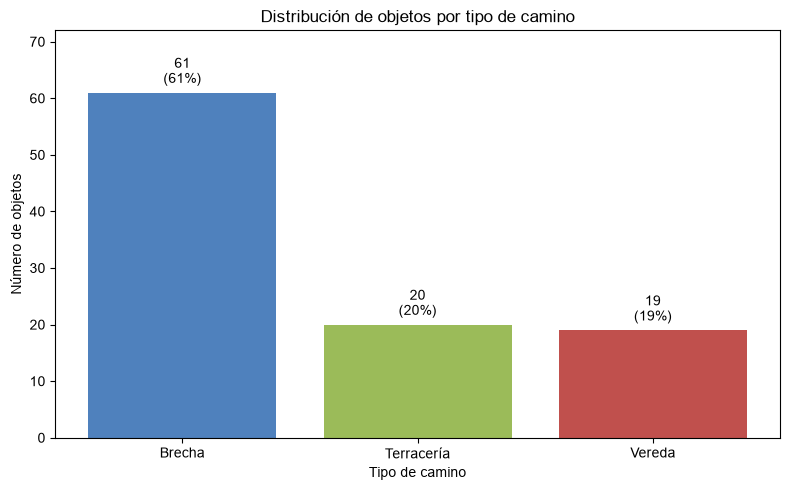

In [128]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"

# Datos obtenidos de la agregación por tipo
conteo_tipos = (
    gdf_muestra_6372["tipo"]
    .value_counts()
    .reindex(["Brecha", "Terracería", "Vereda"])
)

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    conteo_tipos.index,
    conteo_tipos.values,
    color=["#4F81BD", "#9BBB59", "#C0504D"]
)

# Mostrar cantidad y porcentaje sobre cada barra
for barra, valor in zip(barras, conteo_tipos.values):
    porcentaje = valor / conteo_tipos.sum() * 100

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{valor}\n({porcentaje:.0f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Distribución de objetos por tipo de camino")
ax.set_xlabel("Tipo de camino")
ax.set_ylabel("Número de objetos")

ax.set_ylim(0, max(conteo_tipos.values) * 1.18)

plt.tight_layout()
plt.show()

**Resultado:** La visualización muestra un claro predominio de los objetos clasificados como **Brecha**, que representan el 61 % de la muestra analizada. Las categorías **Terracería** y **Vereda** presentan proporciones similares, con 20 % y 19 %, respectivamente.

La representación gráfica facilita la comparación entre categorías y confirma visualmente los resultados obtenidos previamente mediante la agregación por tipo de camino.

### 11.2 Longitud total por tipo de camino

Además de comparar la cantidad de objetos, se representa la **longitud total acumulada** para cada tipo de camino. Esta visualización permite analizar si la participación de las categorías en términos de número de documentos mantiene el mismo comportamiento cuando se considera su extensión espacial.

La comparación complementa la distribución por cantidad de objetos y permite identificar diferencias entre la frecuencia de las categorías y la longitud que representan dentro de la muestra.

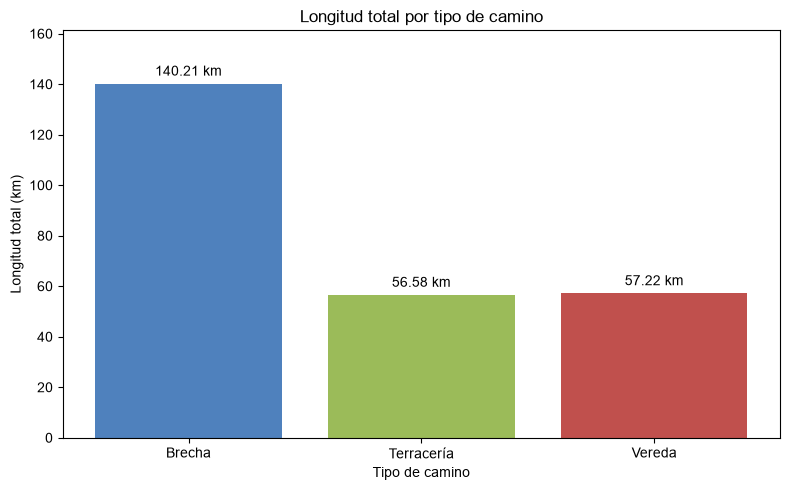

In [129]:
# Longitud total por tipo
longitud_tipo = (
    gdf_muestra_6372
    .groupby("tipo")["longitud_km"]
    .sum()
    .reindex(["Brecha", "Terracería", "Vereda"])
)

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    longitud_tipo.index,
    longitud_tipo.values,
    color=["#4F81BD", "#9BBB59", "#C0504D"]
)

# Mostrar longitud sobre cada barra
for barra, valor in zip(barras, longitud_tipo.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 2,
        f"{valor:.2f} km",
        ha="center",
        va="bottom"
    )

ax.set_title("Longitud total por tipo de camino")
ax.set_xlabel("Tipo de camino")
ax.set_ylabel("Longitud total (km)")

ax.set_ylim(0, max(longitud_tipo.values) * 1.15)

plt.tight_layout()
plt.show()

**Resultado:** La visualización muestra que las **Brechas** concentran la mayor longitud acumulada de la muestra, con 140.21 km. Las categorías Terracería y Vereda presentan valores considerablemente menores y muy similares, con 56.58 km y 57.22 km, respectivamente.

Al comparar estos resultados con la distribución por número de objetos, se observa que una mayor cantidad de elementos no implica necesariamente una diferencia proporcional en longitud. Aunque Terracería cuenta con 20 objetos y Vereda con 19, la longitud total de Vereda es ligeramente mayor. Esto muestra la utilidad de complementar el conteo de documentos con métricas derivadas de la geometría.

### 11.3 Longitud promedio por tipo de camino

Para complementar el análisis de la longitud total, se calcula y representa la **longitud promedio por objeto** en cada categoría.

Esta comparación permite distinguir entre la extensión acumulada de una categoría y la dimensión promedio de los objetos que la integran, aportando una perspectiva adicional sobre el comportamiento espacial de la muestra.

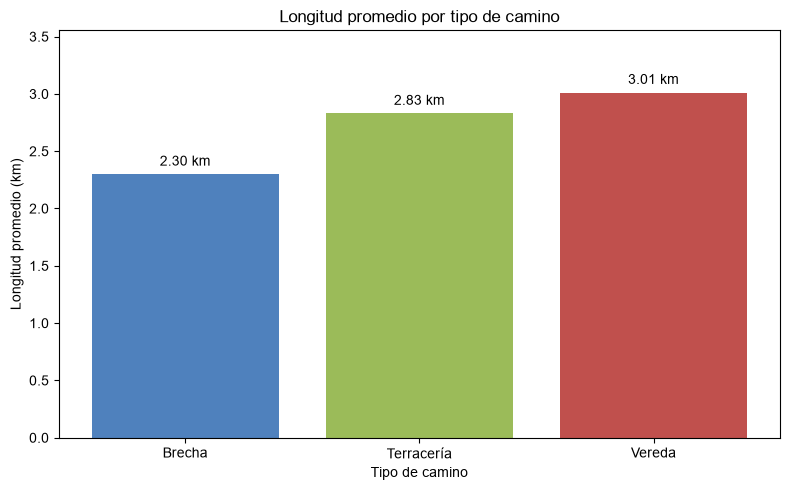

In [130]:
# Longitud promedio por tipo
promedio_tipo = (
    gdf_muestra_6372
    .groupby("tipo")["longitud_km"]
    .mean()
    .reindex(["Brecha", "Terracería", "Vereda"])
)

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    promedio_tipo.index,
    promedio_tipo.values,
    color=["#4F81BD", "#9BBB59", "#C0504D"]
)

# Mostrar longitud promedio sobre cada barra
for barra, valor in zip(barras, promedio_tipo.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.05,
        f"{valor:.2f} km",
        ha="center",
        va="bottom"
    )

ax.set_title("Longitud promedio por tipo de camino")
ax.set_xlabel("Tipo de camino")
ax.set_ylabel("Longitud promedio (km)")

ax.set_ylim(0, max(promedio_tipo.values) * 1.18)

plt.tight_layout()
plt.show()

**Resultado:** La longitud promedio muestra un comportamiento diferente al observado en la cantidad de objetos y en la longitud acumulada. Aunque **Brecha** es la categoría con mayor presencia en la muestra, sus objetos presentan la menor longitud promedio, con 2.30 km.

En contraste, Vereda presenta la mayor longitud promedio, con 3.01 km por objeto, seguida de Terracería con 2.83 km. Esto confirma que una mayor cantidad de objetos o una mayor longitud acumulada no implica necesariamente que los elementos individuales sean, en promedio, más extensos.

La comparación de estos indicadores permite obtener una interpretación más completa de la información, al considerar conjuntamente la frecuencia de los objetos y sus características espaciales.

### 11.4 Mapa de distribución espacial de la muestra

Además de las representaciones estadísticas, la naturaleza geoespacial de los datos permite visualizar la ubicación y distribución de los objetos que integran la muestra.

En esta representación se muestran las 100 geometrías utilizadas durante el análisis, diferenciadas de acuerdo con el tipo de camino. Se conserva la misma simbología empleada en las gráficas anteriores para facilitar la identificación de las categorías y mantener consistencia en la presentación de los resultados.

La visualización espacial permite complementar las métricas obtenidas y observar la disposición geográfica de los elementos analizados.


#### Incorporación del contexto territorial
Para proporcionar referencia espacial a la distribución de los caminos, se incorporan las capas lineales correspondientes a los límites internacionales y a la línea de costa. En conjunto, estas capas permiten representar el contorno territorial de México y contextualizar espacialmente los objetos que integran la muestra.
Antes de generar el mapa se verifica la correcta lectura de ambas capas y sus respectivos sistemas de referencia.

In [131]:
import geopandas as gpd

limite = gpd.read_file(
    ruta_gpkg,
    layer="limite_intna_l"
)

costa = gpd.read_file(
    ruta_gpkg,
    layer="linea_costa_l"
)

print("Límite internacional:")
print("  Objetos:", len(limite))
print("  CRS:", limite.crs)

print("\nLínea de costa:")
print("  Objetos:", len(costa))
print("  CRS:", costa.crs)

Límite internacional:
  Objetos: 2
  CRS: EPSG:6365

Línea de costa:
  Objetos: 2575
  CRS: EPSG:6365


#### Preparación del contexto territorial

Las capas correspondientes al límite internacional y la línea de costa se encuentran originalmente en el sistema EPSG:6365. Para integrarlas con las geometrías utilizadas en el análisis espacial, ambas capas se reproyectan a EPSG:6372.

De esta manera, los límites territoriales, la línea de costa y los caminos de la muestra se representan en un mismo sistema de referencia antes de generar la composición cartográfica.

In [132]:
# Reproyección de las capas de contexto territorial
limite_6372 = limite.to_crs(epsg=6372)
costa_6372 = costa.to_crs(epsg=6372)

print("CRS límite:", limite_6372.crs)
print("CRS costa:", costa_6372.crs)
print("CRS caminos:", gdf_muestra_6372.crs)

CRS límite: EPSG:6372
CRS costa: EPSG:6372
CRS caminos: EPSG:6372


### 11.5 Distribución espacial de los caminos de la muestra

Para complementar las visualizaciones estadísticas, se representa la distribución espacial de los 100 objetos que integran la muestra analizada.

Como referencia territorial se incorporan las capas de **límite internacional** y **línea de costa**, las cuales permiten contextualizar la ubicación de los caminos dentro del territorio nacional. Los objetos se diferencian de acuerdo con su tipo, manteniendo la misma simbología utilizada en las visualizaciones anteriores.

Esta representación permite observar conjuntamente la clasificación de los objetos y su distribución geográfica, aprovechando el componente espacial almacenado en los documentos analizados.

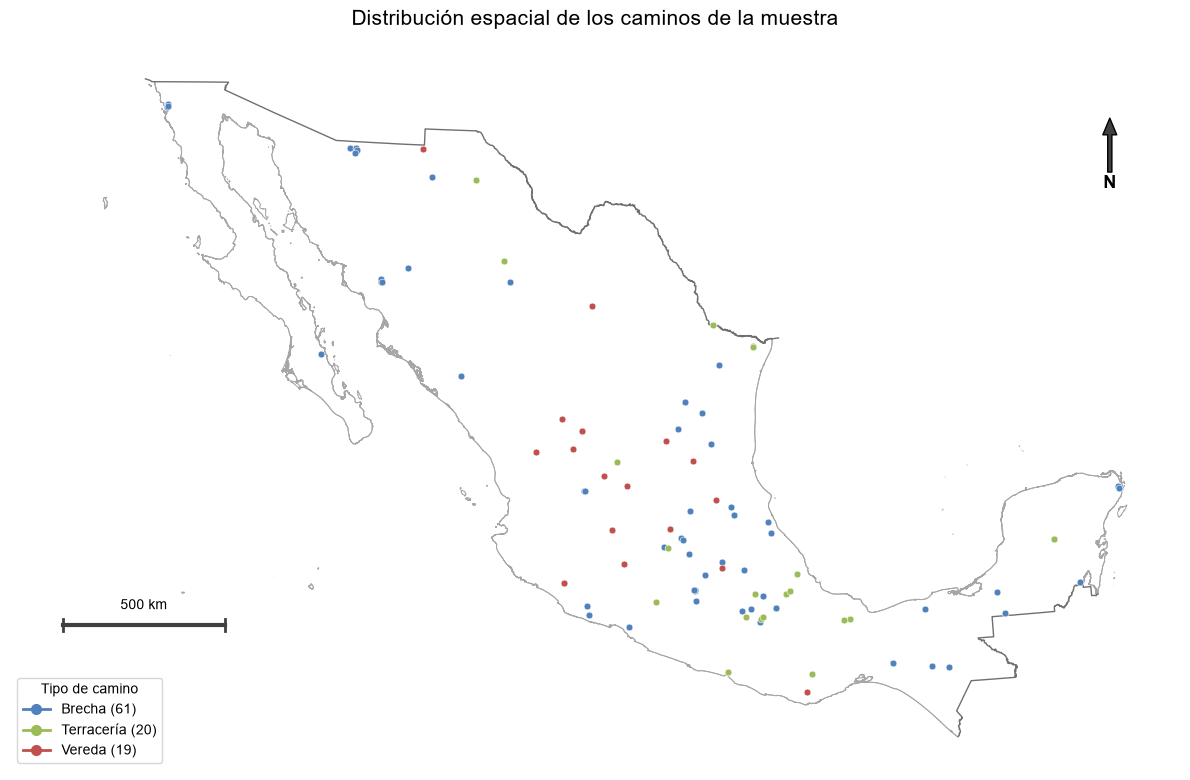

In [133]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"

colores_tipo = {
    "Brecha": "#4F81BD",
    "Terracería": "#9BBB59",
    "Vereda": "#C0504D"
}

fig, ax = plt.subplots(figsize=(12, 8))

# --------------------------------------------------
# 1. Contexto territorial
# --------------------------------------------------

costa_6372.plot(
    ax=ax,
    color="#A6A6A6",
    linewidth=0.7,
    zorder=1
)

limite_6372.plot(
    ax=ax,
    color="#707070",
    linewidth=1.0,
    zorder=2
)

# --------------------------------------------------
# 2. Caminos y puntos de localización
# --------------------------------------------------

for tipo, color in colores_tipo.items():

    subconjunto = gdf_muestra_6372[
        gdf_muestra_6372["tipo"] == tipo
    ]

    # Geometría real
    subconjunto.plot(
        ax=ax,
        color=color,
        linewidth=1.4,
        alpha=0.75,
        zorder=3
    )

    # Punto representativo para mejorar la lectura
    puntos = subconjunto.geometry.interpolate(
        0.5,
        normalized=True
    )

    ax.scatter(
        puntos.x,
        puntos.y,
        s=24,
        color=color,
        edgecolor="white",
        linewidth=0.4,
        zorder=4
    )

# --------------------------------------------------
# 3. Norte
# --------------------------------------------------

ax.annotate(
    "N",
    xy=(0.94, 0.90),
    xytext=(0.94, 0.81),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    arrowprops=dict(
        facecolor="#404040",
        width=3,
        headwidth=10
    )
)

# --------------------------------------------------
# 4. Barra de escala: 500 km
# --------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

longitud_escala = 500000  # 500 km en metros

x_inicio = xmin + (xmax - xmin) * 0.01
y_escala = ymin + (ymax - ymin) * 0.20

ax.plot(
    [x_inicio, x_inicio + longitud_escala],
    [y_escala, y_escala],
    color="#404040",
    linewidth=3,
    zorder=5
)

# Extremos de la barra
altura = (ymax - ymin) * 0.008

ax.plot(
    [x_inicio, x_inicio],
    [y_escala - altura, y_escala + altura],
    color="#404040",
    linewidth=2
)

ax.plot(
    [x_inicio + longitud_escala, x_inicio + longitud_escala],
    [y_escala - altura, y_escala + altura],
    color="#404040",
    linewidth=2
)

ax.text(
    x_inicio + longitud_escala / 2,
    y_escala + (ymax - ymin) * 0.018,
    "500 km",
    ha="center",
    va="bottom",
    fontsize=10
)
# --------------------------------------------------
# 5. Leyenda
# --------------------------------------------------

leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        color=colores_tipo["Brecha"],
        label="Brecha (61)",
        markersize=7,
        linewidth=2
    ),
    Line2D(
        [0], [0],
        marker="o",
        color=colores_tipo["Terracería"],
        label="Terracería (20)",
        markersize=7,
        linewidth=2
    ),
    Line2D(
        [0], [0],
        marker="o",
        color=colores_tipo["Vereda"],
        label="Vereda (19)",
        markersize=7,
        linewidth=2
    )
]

ax.legend(
    handles=leyenda,
    title="Tipo de camino",
    loc="lower left",
    frameon=True
)

# --------------------------------------------------
# 6. Presentación
# --------------------------------------------------

ax.set_title(
    "Distribución espacial de los caminos de la muestra",
    fontsize=15,
    pad=15
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

**Resultado:** La representación cartográfica permite observar que los caminos analizados se distribuyen en diferentes zonas del territorio nacional, por lo que la muestra no se encuentra concentrada en una única región.

La categoría Brecha presenta la mayor cantidad de objetos y también una distribución espacial amplia dentro de la muestra. Las categorías Terracería y Vereda, aunque cuentan con un menor número de elementos, también se localizan en distintas zonas del territorio.

Debido a la escala nacional de representación, se incorporaron puntos sobre las geometrías lineales como apoyo visual para facilitar su localización, conservando simultáneamente la geometría original de los objetos.

La visualización demuestra la utilidad del componente geometry de los documentos, ya que además de conservar la referencia espacial permite integrar los resultados de las consultas y el análisis estadístico en una representación cartográfica.

## 12. Dashboard de resultados

Como etapa de integración, se construye un dashboard que concentra los principales indicadores, resultados estadísticos y elementos cartográficos obtenidos durante el análisis.

El propósito del dashboard es presentar de manera sintética la información más relevante de la muestra, facilitando la consulta conjunta de la cantidad de objetos, su extensión espacial, la distribución por tipo de camino y su localización geográfica.

Para su construcción se reutilizan los resultados obtenidos en las etapas anteriores, evitando realizar cálculos independientes que puedan generar inconsistencias.

### 12.1 Preparación de indicadores principales

Antes de construir la composición visual del dashboard, se preparan los indicadores que sintetizan las principales características de la muestra.

Se consideran cuatro métricas: número total de objetos, longitud total analizada, tipo de camino con mayor presencia y tipo de camino con mayor longitud promedio.

In [134]:
# Indicadores principales del dashboard

total_objetos = len(gdf_muestra_6372)

longitud_total = gdf_muestra_6372["longitud_km"].sum()

tipo_predominante = (
    gdf_muestra_6372["tipo"]
    .value_counts()
    .idxmax()
)

porcentaje_predominante = (
    gdf_muestra_6372["tipo"]
    .value_counts(normalize=True)
    .max() * 100
)

promedio_por_tipo = (
    gdf_muestra_6372
    .groupby("tipo")["longitud_km"]
    .mean()
)

tipo_mayor_promedio = promedio_por_tipo.idxmax()
mayor_promedio = promedio_por_tipo.max()

print("INDICADORES PRINCIPALES")
print("-----------------------")
print(f"Total de objetos: {total_objetos}")
print(f"Longitud total: {longitud_total:.3f} km")
print(
    f"Tipo predominante: {tipo_predominante} "
    f"({porcentaje_predominante:.1f}%)"
)
print(
    f"Mayor longitud promedio: {tipo_mayor_promedio} "
    f"({mayor_promedio:.3f} km)"
)

INDICADORES PRINCIPALES
-----------------------
Total de objetos: 100
Longitud total: 254.016 km
Tipo predominante: Brecha (61.0%)
Mayor longitud promedio: Vereda (3.011 km)


### 12.2 Construcción del dashboard integrado

Con los indicadores previamente calculados se construye un dashboard que integra en una sola vista los principales resultados obtenidos durante el análisis.

La composición reúne indicadores generales, comparaciones por tipo de camino y la distribución espacial de los objetos. Se mantiene la misma simbología utilizada en las visualizaciones anteriores para facilitar la lectura y conservar consistencia entre los diferentes productos generados.

El dashboard constituye una síntesis de los resultados y permite consultar de manera conjunta tanto las características estadísticas como el componente espacial de la muestra.

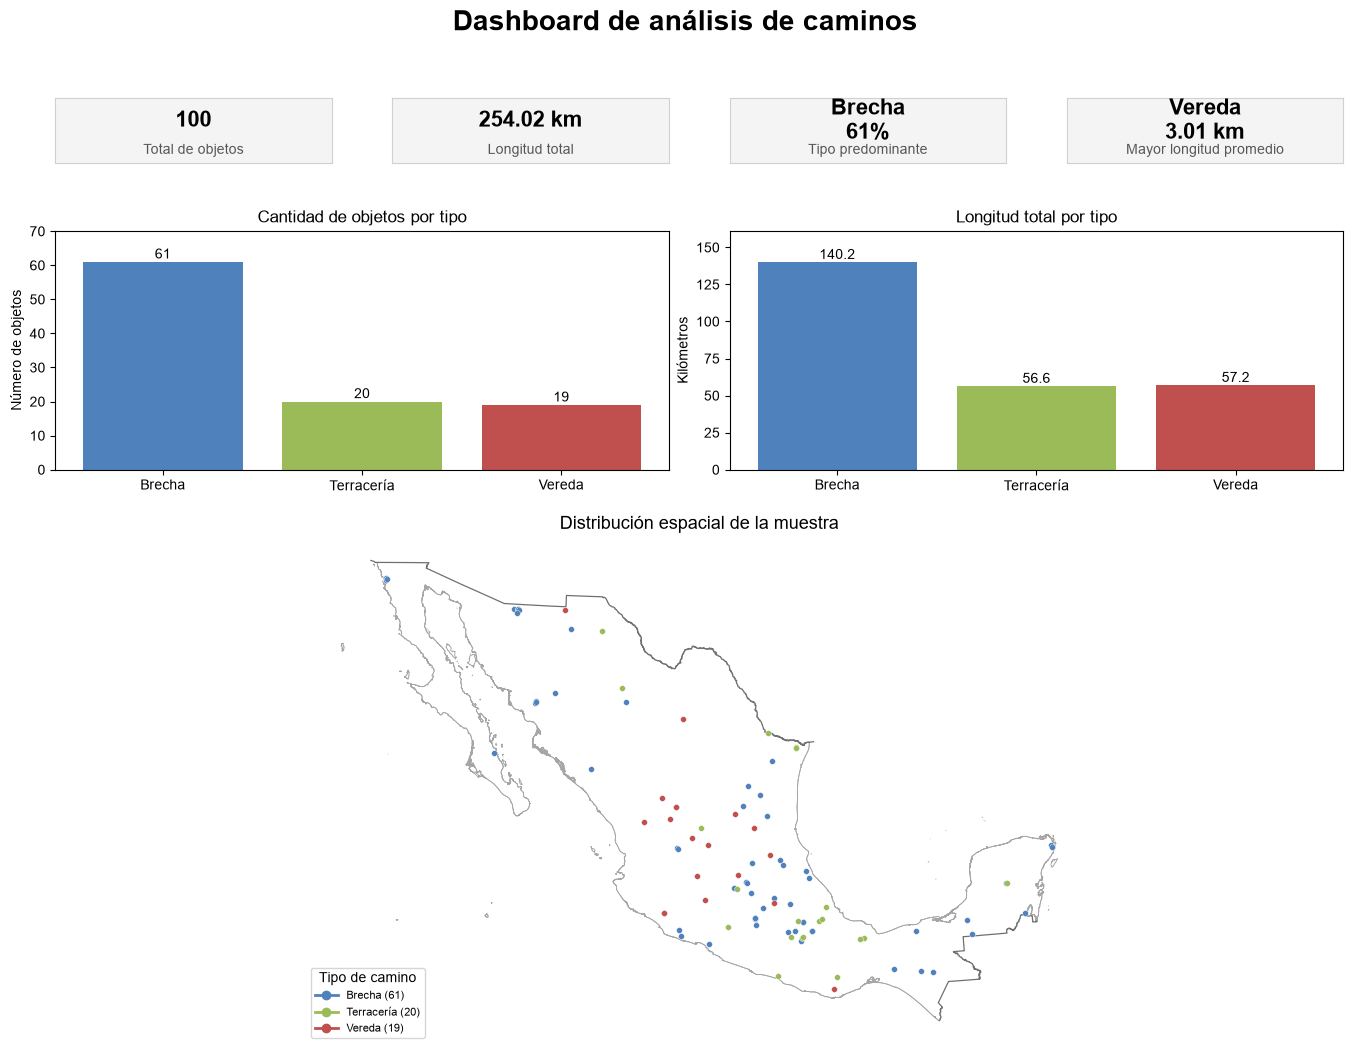

In [135]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Tipografía general del dashboard
plt.rcParams["font.family"] = "Arial"

colores_tipo = {
    "Brecha": "#4F81BD",
    "Terracería": "#9BBB59",
    "Vereda": "#C0504D"
}

orden = ["Brecha", "Terracería", "Vereda"]

# Datos para gráficas
conteo_dashboard = (
    gdf_muestra_6372["tipo"]
    .value_counts()
    .reindex(orden)
)

longitud_dashboard = (
    gdf_muestra_6372
    .groupby("tipo")["longitud_km"]
    .sum()
    .reindex(orden)
)

# --------------------------------------------------
# Estructura general
# --------------------------------------------------

fig = plt.figure(figsize=(14, 11))

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.45, 1.65, 3.5],
    hspace=0.25,
    wspace=0.22
)

fig.suptitle(
    "Dashboard de análisis de caminos",
    fontsize=20,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    top=0.90,
    bottom=0.04,
    left=0.05,
    right=0.97
)

# --------------------------------------------------
# KPI
# --------------------------------------------------

kpis = [
    ("Total de objetos", f"{total_objetos}"),
    ("Longitud total", f"{longitud_total:.2f} km"),
    ("Tipo predominante",
     f"{tipo_predominante}\n{porcentaje_predominante:.0f}%"),
    ("Mayor longitud promedio",
     f"{tipo_mayor_promedio}\n{mayor_promedio:.2f} km")
]

for i, (titulo, valor) in enumerate(kpis):

    ax_kpi = fig.add_subplot(gs[0, i])

    ax_kpi.text(
        0.5, 0.65,
        valor,
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold"
    )

    ax_kpi.text(
        0.5, 0.20,
        titulo,
        ha="center",
        va="center",
        fontsize=10,
        color="#555555"
    )

    ax_kpi.set_facecolor("#F4F4F4")

    for spine in ax_kpi.spines.values():
        spine.set_color("#D0D0D0")

    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])

# --------------------------------------------------
# Cantidad de objetos
# --------------------------------------------------

ax1 = fig.add_subplot(gs[1, 0:2])

barras1 = ax1.bar(
    conteo_dashboard.index,
    conteo_dashboard.values,
    color=[colores_tipo[t] for t in orden]
)

ax1.set_title("Cantidad de objetos por tipo")
ax1.set_ylabel("Número de objetos")

for barra, valor in zip(barras1, conteo_dashboard.values):
    ax1.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 1,
        f"{valor}",
        ha="center"
    )
ax1.set_ylim(
    0,
    max(conteo_dashboard.values) * 1.15
)

# --------------------------------------------------
# Longitud total
# --------------------------------------------------

ax2 = fig.add_subplot(gs[1, 2:4])

barras2 = ax2.bar(
    longitud_dashboard.index,
    longitud_dashboard.values,
    color=[colores_tipo[t] for t in orden]
)

ax2.set_title("Longitud total por tipo")
ax2.set_ylabel("Kilómetros")

for barra, valor in zip(barras2, longitud_dashboard.values):
    ax2.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 2,
        f"{valor:.1f}",
        ha="center"
    )

ax2.set_ylim(
    0,
    max(longitud_dashboard.values) * 1.15
)

# --------------------------------------------------
# Mapa
# --------------------------------------------------

ax_mapa = fig.add_subplot(gs[2, :])

costa_6372.plot(
    ax=ax_mapa,
    color="#A6A6A6",
    linewidth=0.6,
    zorder=1
)

limite_6372.plot(
    ax=ax_mapa,
    color="#707070",
    linewidth=0.9,
    zorder=2
)

for tipo, color in colores_tipo.items():

    subconjunto = gdf_muestra_6372[
        gdf_muestra_6372["tipo"] == tipo
    ]

    subconjunto.plot(
        ax=ax_mapa,
        color=color,
        linewidth=1.2,
        alpha=0.7,
        zorder=3
    )

    puntos = subconjunto.geometry.interpolate(
        0.5,
        normalized=True
    )

    ax_mapa.scatter(
        puntos.x,
        puntos.y,
        s=18,
        color=color,
        edgecolor="white",
        linewidth=0.3,
        zorder=4
    )

ax_mapa.set_title(
    "Distribución espacial de la muestra",
    fontsize=13
)

leyenda = [
    Line2D([0], [0], marker="o",
           color=colores_tipo[tipo],
           label=f"{tipo} ({conteo_dashboard[tipo]})",
           markersize=6,
           linewidth=2)
    for tipo in orden
]

ax_mapa.legend(
    handles=leyenda,
    title="Tipo de camino",
    loc="lower left",
    fontsize=8
)

ax_mapa.set_aspect("equal")
ax_mapa.set_axis_off()

plt.show()

### 12.3 Dashboard interactivo

Como complemento al dashboard general, se incorpora una versión interactiva que permite seleccionar el tipo de camino que se desea analizar.

Al modificar la selección, los indicadores, las gráficas y la representación cartográfica se actualizan utilizando únicamente los objetos correspondientes a la categoría elegida. La opción **Todos** permite recuperar nuevamente la vista completa de la muestra.

Esta funcionalidad facilita la exploración de los resultados y permite comparar de manera dinámica el comportamiento de Brecha, Terracería y Vereda.

In [136]:
import ipywidgets as widgets
from IPython.display import display

selector_tipo = widgets.Dropdown(
    options=["Todos", "Brecha", "Terracería", "Vereda"],
    value="Todos",
    description="Tipo:"
)

display(selector_tipo)

Dropdown(description='Tipo:', options=('Todos', 'Brecha', 'Terracería', 'Vereda'), value='Todos')

#### 12.3.1 Comprobación del filtro interactivo

In [137]:
from IPython.display import clear_output

salida_filtro = widgets.Output()

def filtrar_tipo(change=None):
    
    with salida_filtro:
        clear_output(wait=True)

        seleccion = selector_tipo.value

        if seleccion == "Todos":
            datos_filtrados = gdf_muestra_6372.copy()
        else:
            datos_filtrados = gdf_muestra_6372[
                gdf_muestra_6372["tipo"] == seleccion
            ].copy()

        print("Selección:", seleccion)
        print("Objetos encontrados:", len(datos_filtrados))
        print(
            "Longitud total:",
            f"{datos_filtrados['longitud_km'].sum():.3f} km"
        )

selector_tipo.observe(
    filtrar_tipo,
    names="value"
)

display(salida_filtro)

# Mostrar resultado inicial
filtrar_tipo()


Output()

**Resultado:** El selector permite modificar dinámicamente la categoría analizada entre Todos, Brecha, Terracería y Vereda. Al realizar una selección, el número de objetos y la longitud total se actualizan automáticamente de acuerdo con los registros correspondientes, comprobando el funcionamiento del filtrado interactivo.

#### 13.3.2 Integración del filtro con el dashboard

In [138]:
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output
from matplotlib.lines import Line2D

# Tipografía general
plt.rcParams["font.family"] = "Arial"

# ------------------------------------------------------------
# 1. Configuración general
# ------------------------------------------------------------

colores_tipo = {
    "Brecha": "#4F81BD",
    "Terracería": "#9BBB59",
    "Vereda": "#C0504D"
}

orden = ["Brecha", "Terracería", "Vereda"]

# Selector integrado al dashboard
selector_dashboard = widgets.Dropdown(
    options=["Todos", "Brecha", "Terracería", "Vereda"],
    value="Todos",
    description="Tipo:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="260px")
)

# Área donde se actualizará el dashboard
salida_dashboard = widgets.Output()


# ------------------------------------------------------------
# 2. Función para actualizar el dashboard
# ------------------------------------------------------------

def actualizar_dashboard(change=None):

    with salida_dashboard:

        # Limpiar únicamente la salida anterior del dashboard
        clear_output(wait=True)

        seleccion = selector_dashboard.value

        # ----------------------------------------------------
        # FILTRO DE DATOS
        # ----------------------------------------------------

        if seleccion == "Todos":
            datos = gdf_muestra_6372.copy()
        else:
            datos = gdf_muestra_6372[
                gdf_muestra_6372["tipo"] == seleccion
            ].copy()

        if datos.empty:
            print("No existen datos para la selección.")
            return

        # ----------------------------------------------------
        # INDICADORES
        # ----------------------------------------------------

        total = len(datos)

        longitud_total_filtro = (
            datos["longitud_km"].sum()
        )

        longitud_promedio_filtro = (
            datos["longitud_km"].mean()
        )

        if seleccion == "Todos":

            conteo_general = datos["tipo"].value_counts()

            tipo_principal = conteo_general.idxmax()

            porcentaje_principal = (
                conteo_general.max()
                / conteo_general.sum()
                * 100
            )

            tercer_kpi_titulo = "Tipo predominante"

            tercer_kpi_valor = (
                f"{tipo_principal}\n"
                f"{porcentaje_principal:.0f}%"
            )

        else:

            tercer_kpi_titulo = "Tipo seleccionado"

            tercer_kpi_valor = seleccion

        # ----------------------------------------------------
        # DATOS PARA LAS GRÁFICAS
        # ----------------------------------------------------

        conteo = (
            datos["tipo"]
            .value_counts()
            .reindex(orden, fill_value=0)
        )

        longitud_tipo = (
            datos
            .groupby("tipo")["longitud_km"]
            .sum()
            .reindex(orden, fill_value=0)
        )

        # ----------------------------------------------------
        # CREAR FIGURA
        # ----------------------------------------------------

        fig = plt.figure(
            figsize=(14, 11),
            facecolor="white"
        )

        gs = fig.add_gridspec(
            3,
            4,
            height_ratios=[0.45, 1.65, 3.5],
            hspace=0.25,
            wspace=0.22
        )

        # Título dinámico
        if seleccion == "Todos":
            titulo_dashboard = (
                "Dashboard de análisis de caminos"
            )
        else:
            titulo_dashboard = (
                f"Dashboard de análisis de caminos - {seleccion}"
            )

        fig.suptitle(
            titulo_dashboard,
            fontsize=20,
            fontweight="bold",
            y=0.98
        )

        fig.subplots_adjust(
            top=0.90,
            bottom=0.04,
            left=0.05,
            right=0.97
        )

        # ----------------------------------------------------
        # 3. KPI
        # ----------------------------------------------------

        kpis = [
            (
                "Total de objetos",
                f"{total}"
            ),
            (
                "Longitud total",
                f"{longitud_total_filtro:.2f} km"
            ),
            (
                tercer_kpi_titulo,
                tercer_kpi_valor
            ),
            (
                "Longitud promedio",
                f"{longitud_promedio_filtro:.2f} km"
            )
        ]

        for i, (titulo_kpi, valor_kpi) in enumerate(kpis):

            ax_kpi = fig.add_subplot(
                gs[0, i]
            )

            ax_kpi.set_facecolor(
                "#F4F4F4"
            )

            ax_kpi.text(
                0.5,
                0.62,
                valor_kpi,
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold"
            )

            ax_kpi.text(
                0.5,
                0.18,
                titulo_kpi,
                ha="center",
                va="center",
                fontsize=10,
                color="#555555"
            )

            for spine in ax_kpi.spines.values():
                spine.set_color(
                    "#D0D0D0"
                )

            ax_kpi.set_xticks([])
            ax_kpi.set_yticks([])

        # ----------------------------------------------------
        # 4. GRÁFICA: CANTIDAD DE OBJETOS
        # ----------------------------------------------------

        ax1 = fig.add_subplot(
            gs[1, 0:2]
        )

        barras1 = ax1.bar(
            conteo.index,
            conteo.values,
            color=[
                colores_tipo[tipo]
                for tipo in orden
            ]
        )

        ax1.set_title(
            "Cantidad de objetos por tipo",
            fontsize=12,
            fontweight="bold"
        )

        ax1.set_ylabel(
            "Número de objetos"
        )

        max_conteo = max(
            conteo.max(),
            1
        )

        # Margen superior para evitar
        # que los valores salgan del recuadro
        ax1.set_ylim(
            0,
            max_conteo * 1.18
        )

        for barra, valor in zip(
            barras1,
            conteo.values
        ):

            if valor > 0:

                ax1.text(
                    barra.get_x()
                    + barra.get_width() / 2,
                    barra.get_height()
                    + max_conteo * 0.025,
                    f"{valor}",
                    ha="center",
                    va="bottom",
                    fontsize=10
                )

        ax1.spines["top"].set_visible(False)
        ax1.spines["right"].set_visible(False)

        # ----------------------------------------------------
        # 5. GRÁFICA: LONGITUD TOTAL
        # ----------------------------------------------------

        ax2 = fig.add_subplot(
            gs[1, 2:4]
        )

        barras2 = ax2.bar(
            longitud_tipo.index,
            longitud_tipo.values,
            color=[
                colores_tipo[tipo]
                for tipo in orden
            ]
        )

        ax2.set_title(
            "Longitud total por tipo",
            fontsize=12,
            fontweight="bold"
        )

        ax2.set_ylabel(
            "Kilómetros"
        )

        max_longitud = max(
            longitud_tipo.max(),
            1
        )

        # Margen superior para que las
        # etiquetas queden dentro
        ax2.set_ylim(
            0,
            max_longitud * 1.18
        )

        for barra, valor in zip(
            barras2,
            longitud_tipo.values
        ):

            if valor > 0:

                ax2.text(
                    barra.get_x()
                    + barra.get_width() / 2,
                    barra.get_height()
                    + max_longitud * 0.025,
                    f"{valor:.1f}",
                    ha="center",
                    va="bottom",
                    fontsize=10
                )

        ax2.spines["top"].set_visible(False)
        ax2.spines["right"].set_visible(False)

        # ----------------------------------------------------
        # 6. MAPA
        # ----------------------------------------------------

        ax_mapa = fig.add_subplot(
            gs[2, :]
        )

        # Línea de costa
        costa_6372.plot(
            ax=ax_mapa,
            color="#A6A6A6",
            linewidth=0.6,
            zorder=1
        )

        # Límites internacionales
        limite_6372.plot(
            ax=ax_mapa,
            color="#707070",
            linewidth=0.9,
            zorder=2
        )

        # Caminos
        for tipo in orden:

            subconjunto = datos[
                datos["tipo"] == tipo
            ]

            if subconjunto.empty:
                continue

            color = colores_tipo[tipo]

            # Geometría lineal original
            subconjunto.plot(
                ax=ax_mapa,
                color=color,
                linewidth=1.2,
                alpha=0.75,
                zorder=3
            )

            # Punto de apoyo para
            # localización a escala nacional
            puntos = (
                subconjunto.geometry
                .interpolate(
                    0.5,
                    normalized=True
                )
            )

            ax_mapa.scatter(
                puntos.x,
                puntos.y,
                s=20,
                color=color,
                edgecolor="white",
                linewidth=0.3,
                zorder=4
            )

        ax_mapa.set_title(
            "Distribución espacial de la selección",
            fontsize=13,
            fontweight="bold"
        )

        # ----------------------------------------------------
        # 7. NORTE
        # ----------------------------------------------------

        ax_mapa.annotate(
            "N",
            xy=(0.94, 0.90),
            xytext=(0.94, 0.81),
            xycoords="axes fraction",
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            arrowprops=dict(
                facecolor="#404040",
                width=3,
                headwidth=10
            )
        )

        # ----------------------------------------------------
        # 8. ESCALA GRÁFICA
        # ----------------------------------------------------

        xmin, xmax = ax_mapa.get_xlim()
        ymin, ymax = ax_mapa.get_ylim()

        # 500 km en metros
        longitud_escala = 500000

        # Posición inferior central
        x_inicio = (
            xmin
            + (xmax - xmin) * 0.40
        )

        y_escala = (
            ymin
            + (ymax - ymin) * 0.07
        )

        ax_mapa.plot(
            [
                x_inicio,
                x_inicio + longitud_escala
            ],
            [
                y_escala,
                y_escala
            ],
            color="#404040",
            linewidth=3,
            zorder=5
        )

        altura = (
            (ymax - ymin) * 0.008
        )

        # Extremo izquierdo
        ax_mapa.plot(
            [
                x_inicio,
                x_inicio
            ],
            [
                y_escala - altura,
                y_escala + altura
            ],
            color="#404040",
            linewidth=2,
            zorder=5
        )

        # Extremo derecho
        ax_mapa.plot(
            [
                x_inicio + longitud_escala,
                x_inicio + longitud_escala
            ],
            [
                y_escala - altura,
                y_escala + altura
            ],
            color="#404040",
            linewidth=2,
            zorder=5
        )

        ax_mapa.text(
            x_inicio + longitud_escala / 2,
            y_escala
            + (ymax - ymin) * 0.018,
            "500 km",
            ha="center",
            va="bottom",
            fontsize=9
        )

        # ----------------------------------------------------
        # 9. LEYENDA DINÁMICA
        # ----------------------------------------------------

        elementos_leyenda = []

        for tipo in orden:

            cantidad = int(
                conteo[tipo]
            )

            if cantidad > 0:

                elementos_leyenda.append(
                    Line2D(
                        [0],
                        [0],
                        marker="o",
                        color=colores_tipo[tipo],
                        label=(
                            f"{tipo} ({cantidad})"
                        ),
                        markersize=6,
                        linewidth=2
                    )
                )

        if elementos_leyenda:

            ax_mapa.legend(
                handles=elementos_leyenda,
                title="Tipo de camino",
                loc="lower left",
                fontsize=8,
                frameon=True
            )

        ax_mapa.set_aspect(
            "equal"
        )

        ax_mapa.set_axis_off()

        plt.show()


# ------------------------------------------------------------
# 10. EVENTO DEL SELECTOR
# ------------------------------------------------------------

selector_dashboard.observe(
    actualizar_dashboard,
    names="value"
)


# ------------------------------------------------------------
# 11. INTEGRAR SELECTOR + DASHBOARD
# ------------------------------------------------------------

titulo_filtro = widgets.HTML(
    value=(
        "<b>Filtrar dashboard por tipo de camino:</b>"
    )
)

dashboard_interactivo = widgets.VBox(
    [
        titulo_filtro,
        selector_dashboard,
        salida_dashboard
    ],
    layout=widgets.Layout(
        width="100%"
    )
)


# ------------------------------------------------------------
# 12. MOSTRAR DASHBOARD
# ------------------------------------------------------------

display(
    dashboard_interactivo
)

# Vista inicial
actualizar_dashboard()

## 13\. Conclusiones y alcance

### 13.1 Conclusiones

El desarrollo permitió trabajar con información geoespacial mediante un enfoque documental, integrando en una misma estructura los atributos descriptivos y la geometría de los objetos. A partir de los documentos generados fue posible reproducir operaciones de consulta, filtrado y agregación, y posteriormente utilizar los resultados para realizar análisis estadísticos y espaciales.

El análisis mostró también la importancia de considerar diferentes perspectivas de la información. La cantidad de objetos permitió identificar la categoría predominante, mientras que las métricas derivadas de la geometría mostraron que esta distribución no necesariamente se mantiene al comparar la longitud total o la longitud promedio de los elementos. De esta manera, el componente espacial complementó la información obtenida mediante las consultas sobre atributos.

La incorporación de la representación cartográfica permitió conservar el contexto geográfico de los resultados y comprobar que la geometría almacenada en los documentos puede aprovecharse posteriormente para análisis y visualización, además de funcionar como un atributo de localización.

Finalmente, la integración de los indicadores, las gráficas y el mapa en un dashboard interactivo permitió concentrar los principales resultados en una sola vista. El filtrado por tipo de camino facilita explorar de manera dinámica las diferencias entre las categorías sin modificar el conjunto de datos original.

### 13.2 Alcance y limitaciones

El entorno utilizado para el desarrollo no permitió disponer de una instalación local de MongoDB. Por esta razón, las consultas planteadas con sintaxis NoSQL no fueron ejecutadas directamente sobre una instancia de MongoDB, sino reproducidas mediante Python sobre los documentos JSON previamente generados.

Esta condición limita la práctica en lo relacionado con la ejecución y evaluación de las operaciones dentro del propio gestor de base de datos, pero no impide demostrar la estructura documental, la lógica de las consultas, los filtros y las agregaciones, así como el procesamiento posterior de sus resultados.

Por lo tanto, el trabajo desarrollado representa una implementación funcional del flujo de preparación, consulta, análisis y visualización de los datos dentro de las condiciones disponibles. Como continuación, los mismos documentos y consultas podrían incorporarse a una instancia de MongoDB para evaluar aspectos propios del gestor, como almacenamiento, índices, rendimiento y ejecución directa de consultas sobre la colección.